In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from scipy.stats import friedmanchisquare, f_oneway

import warnings
warnings.filterwarnings("ignore")

In [11]:
# Load the Bank Note Authentication dataset

df = pd.read_csv("BankNote_Authentication.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (1372, 5)

First 5 rows:


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Column Names:
['variance', 'skewness', 'curtosis', 'entropy', 'class']


In [10]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df.iloc[:, -1].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing Values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class Distribution:
class
0    762
1    610
Name: count, dtype: int64


In [12]:
# Features
X = df.iloc[:, :-1]

# Target
y = df.iloc[:, -1]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Features:
['variance', 'skewness', 'curtosis', 'entropy']

Target:
class

Feature Shape: (1372, 4)
Target Shape: (1372,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1097
Testing samples: 275


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [15]:
# Logistic Regression without effective L2 regularization

logistic_no_reg = LogisticRegression(
    penalty='l2',
    C=1e10,
    max_iter=1000
)

logistic_no_reg.fit(X_train_scaled, y_train)

train_pred_no_reg = logistic_no_reg.predict(X_train_scaled)
test_pred_no_reg = logistic_no_reg.predict(X_test_scaled)

train_acc_no_reg = accuracy_score(y_train, train_pred_no_reg)
test_acc_no_reg = accuracy_score(y_test, test_pred_no_reg)

print("Logistic Regression - Without L2 Regularization")
print("Training Accuracy:", train_acc_no_reg)
print("Test Accuracy:", test_acc_no_reg)

Logistic Regression - Without L2 Regularization
Training Accuracy: 0.9908842297174111
Test Accuracy: 0.9854545454545455


In [16]:
logistic_l2 = LogisticRegression(
    penalty='l2',
    C=1.0,
    max_iter=1000
)

logistic_l2.fit(X_train_scaled, y_train)

train_pred_l2 = logistic_l2.predict(X_train_scaled)
test_pred_l2 = logistic_l2.predict(X_test_scaled)

train_acc_l2 = accuracy_score(y_train, train_pred_l2)
test_acc_l2 = accuracy_score(y_test, test_pred_l2)

print("Logistic Regression - With L2 Regularization")
print("Training Accuracy:", train_acc_l2)
print("Test Accuracy:", test_acc_l2)

Logistic Regression - With L2 Regularization
Training Accuracy: 0.9845031905195989
Test Accuracy: 0.9709090909090909


In [17]:
baseline_results = pd.DataFrame({
    'Model': [
        'Logistic Regression - No L2',
        'Logistic Regression - L2'
    ],
    'Training Accuracy': [
        train_acc_no_reg,
        train_acc_l2
    ],
    'Test Accuracy': [
        test_acc_no_reg,
        test_acc_l2
    ]
})

display(baseline_results)

,Model,Training Accuracy,Test Accuracy
0,Logistic Regression - No L2,0.990884,0.985455
1,Logistic Regression - L2,0.984503,0.970909


In [18]:
lambda_values = np.logspace(-4, 4, 15)

train_accuracies = []
test_accuracies = []

for lam in lambda_values:

    C_value = 1 / lam

    model = LogisticRegression(
        penalty='l2',
        C=C_value,
        max_iter=1000
    )

    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_accuracies.append(
        accuracy_score(y_train, train_pred)
    )

    test_accuracies.append(
        accuracy_score(y_test, test_pred)
    )

regularization_results = pd.DataFrame({
    'Lambda': lambda_values,
    'Training Accuracy': train_accuracies,
    'Test Accuracy': test_accuracies
})

display(regularization_results)

,Lambda,Training Accuracy,Test Accuracy
0,0.000100,0.990884,0.985455
1,0.000373,0.990884,0.985455
2,0.001389,0.990884,0.985455
3,0.005179,0.990884,0.985455
4,0.019307,0.990884,0.985455
5,0.071969,0.992707,0.985455
6,0.268270,0.987238,0.978182
7,1.000000,0.984503,0.970909
8,3.727594,0.982680,0.970909
9,13.894955,0.974476,0.970909


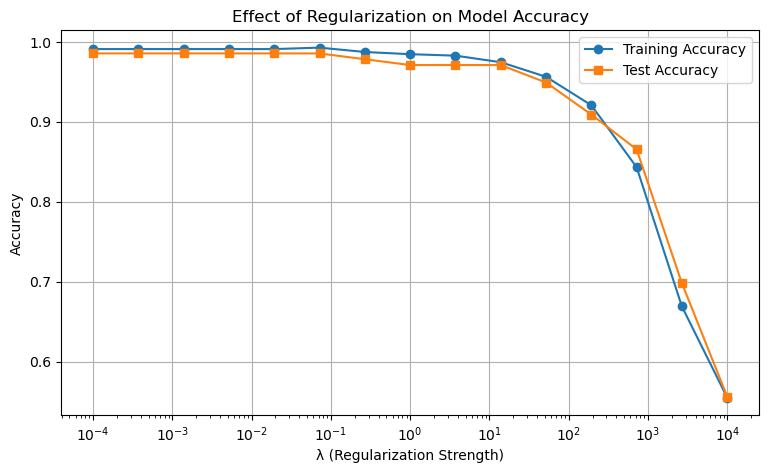

In [19]:
plt.figure(figsize=(9, 5))

plt.semilogx(
    lambda_values,
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.semilogx(
    lambda_values,
    test_accuracies,
    marker='s',
    label='Test Accuracy'
)

plt.xlabel("λ (Regularization Strength)")
plt.ylabel("Accuracy")
plt.title("Effect of Regularization on Model Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [20]:
best_index = np.argmax(test_accuracies)

best_lambda = lambda_values[best_index]
best_test_accuracy = test_accuracies[best_index]

print("Best λ:", best_lambda)
print("Best Test Accuracy:", best_test_accuracy)

Best λ: 0.0001
Best Test Accuracy: 0.9854545454545455


In [21]:
selected_features = [
    'variance',
    'skewness',
    'curtosis'
]

X_3d = df[selected_features]
y_3d = df['class']

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X_3d,
    y_3d,
    test_size=0.20,
    random_state=42,
    stratify=y_3d
)

scaler_3d = StandardScaler()

X3_train_scaled = scaler_3d.fit_transform(X3_train)
X3_test_scaled = scaler_3d.transform(X3_test)

model_3d = LogisticRegression(
    max_iter=1000
)

model_3d.fit(X3_train_scaled, y3_train)

print(
    "3D Model Accuracy:",
    accuracy_score(
        y3_test,
        model_3d.predict(X3_test_scaled)
    )
)

3D Model Accuracy: 0.9709090909090909


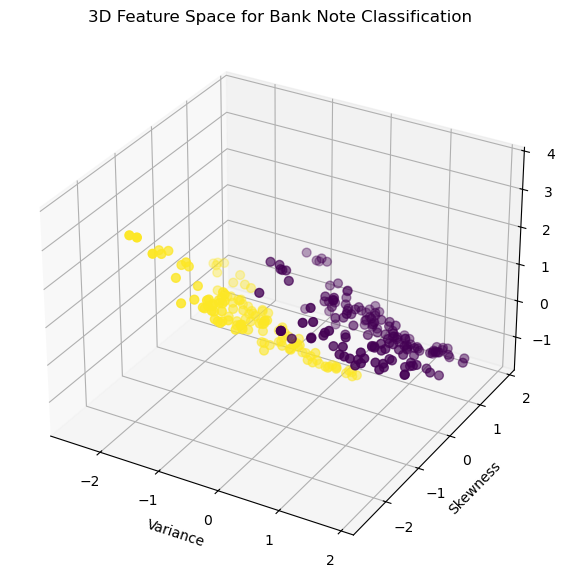

In [22]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X3_test_scaled[:, 0],
    X3_test_scaled[:, 1],
    X3_test_scaled[:, 2],
    c=y3_test,
    cmap='viridis',
    s=40
)

ax.set_xlabel('Variance')
ax.set_ylabel('Skewness')
ax.set_zlabel('Curtosis')

ax.set_title("3D Feature Space for Bank Note Classification")

plt.show()

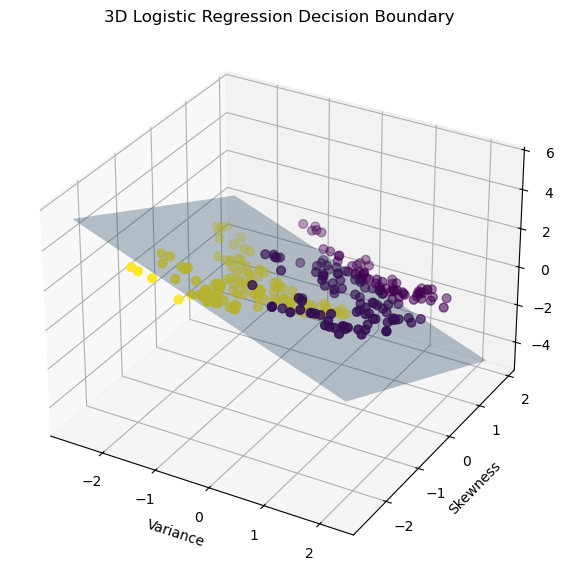

In [23]:
# Create grid for first two features
x1 = np.linspace(
    X3_train_scaled[:, 0].min(),
    X3_train_scaled[:, 0].max(),
    30
)

x2 = np.linspace(
    X3_train_scaled[:, 1].min(),
    X3_train_scaled[:, 1].max(),
    30
)

x1_grid, x2_grid = np.meshgrid(x1, x2)

# Logistic equation:
# w1*x1 + w2*x2 + w3*x3 + b = 0

w = model_3d.coef_[0]
b = model_3d.intercept_[0]

x3_grid = -(w[0] * x1_grid + w[1] * x2_grid + b) / w[2]

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Data points
ax.scatter(
    X3_test_scaled[:, 0],
    X3_test_scaled[:, 1],
    X3_test_scaled[:, 2],
    c=y3_test,
    cmap='viridis',
    s=40
)

# Decision plane
ax.plot_surface(
    x1_grid,
    x2_grid,
    x3_grid,
    alpha=0.3
)

ax.set_xlabel('Variance')
ax.set_ylabel('Skewness')
ax.set_zlabel('Curtosis')

ax.set_title("3D Logistic Regression Decision Boundary")

plt.show()

In [24]:
neural_network = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

neural_network.fit(
    X_train_scaled,
    y_train
)

nn_train_pred = neural_network.predict(X_train_scaled)
nn_test_pred = neural_network.predict(X_test_scaled)

In [26]:
def evaluate_model(model_name, y_train, train_pred, y_test, test_pred):

    return {
        'Model': model_name,
        'Training Accuracy': accuracy_score(y_train, train_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'Precision': precision_score(y_test, test_pred),
        'Recall': recall_score(y_test, test_pred),
        'F1 Score': f1_score(y_test, test_pred)
    }

In [27]:
comparison_results = []

# Logistic Regression
comparison_results.append(
    evaluate_model(
        "Logistic Regression",
        y_train,
        train_pred_l2,
        y_test,
        test_pred_l2
    )
)

# Neural Network
comparison_results.append(
    evaluate_model(
        "Neural Network",
        y_train,
        nn_train_pred,
        y_test,
        nn_test_pred
    )
)

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Model,Training Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.984503,0.970909,0.938462,1.0,0.968254
1,Neural Network,1.000000,1.000000,1.000000,1.0,1.000000


In [28]:
print("LOGISTIC REGRESSION")
print(
    classification_report(
        y_test,
        test_pred_l2
    )
)

print("\nNEURAL NETWORK")
print(
    classification_report(
        y_test,
        nn_test_pred
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275


NEURAL NETWORK
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



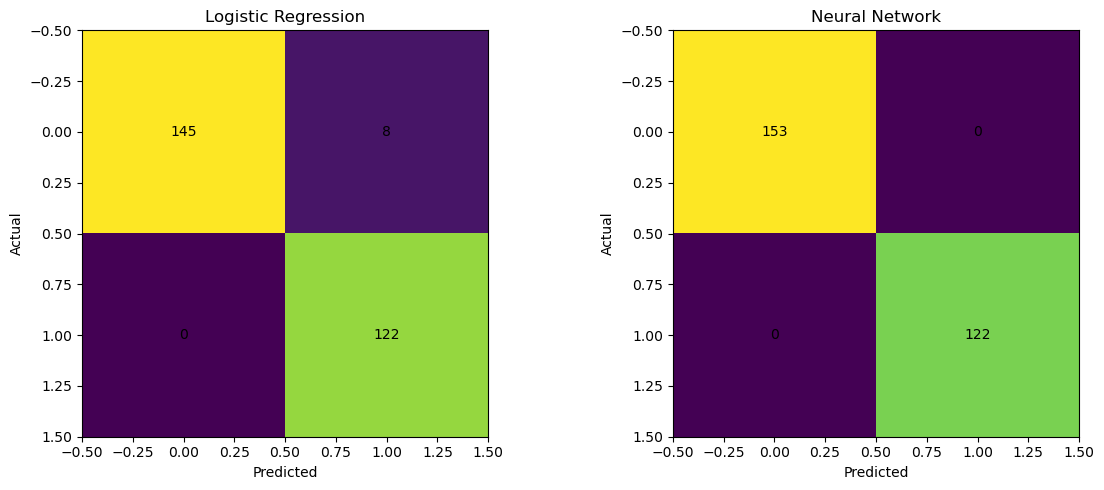

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_logistic = confusion_matrix(y_test, test_pred_l2)
cm_nn = confusion_matrix(y_test, nn_test_pred)

axes[0].imshow(cm_logistic)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm_logistic[i, j],
                     ha='center', va='center')

axes[1].imshow(cm_nn)
axes[1].set_title("Neural Network")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

for i in range(2):
    for j in range(2):
        axes[1].text(j, i, cm_nn[i, j],
                     ha='center', va='center')

plt.tight_layout()
plt.show()

In [30]:
# PCA on the scaled training data

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_scaled.shape[1])
print("Reduced number of features:", X_train_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Explained:",
    sum(pca.explained_variance_ratio_)
)

Original number of features: 4
Reduced number of features: 2

Explained Variance Ratio:
[0.54191611 0.32715148]

Total Variance Explained: 0.8690675906324054


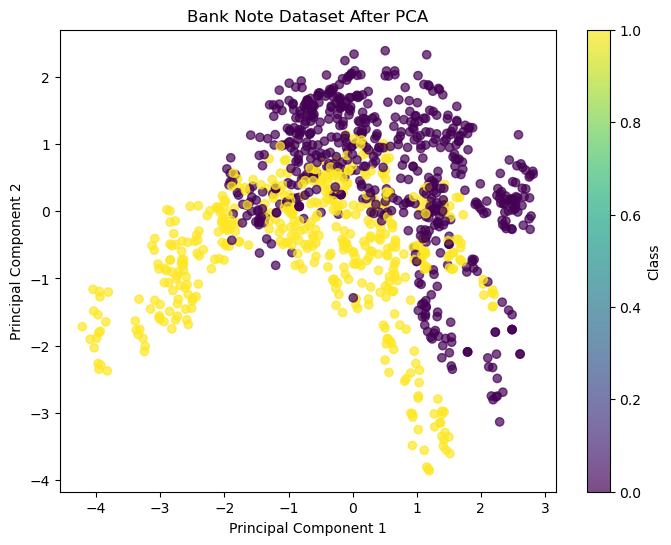

In [31]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap='viridis',
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Bank Note Dataset After PCA")

plt.colorbar(label="Class")

plt.show()

In [32]:
logistic_pca = LogisticRegression(
    penalty='l2',
    C=1.0,
    max_iter=1000
)

logistic_pca.fit(
    X_train_pca,
    y_train
)

pca_train_pred = logistic_pca.predict(X_train_pca)
pca_test_pred = logistic_pca.predict(X_test_pca)

pca_train_accuracy = accuracy_score(
    y_train,
    pca_train_pred
)

pca_test_accuracy = accuracy_score(
    y_test,
    pca_test_pred
)

print("PCA Logistic Regression")
print("Training Accuracy:", pca_train_accuracy)
print("Test Accuracy:", pca_test_accuracy)

PCA Logistic Regression
Training Accuracy: 0.7493163172288059
Test Accuracy: 0.7963636363636364


In [33]:
pca_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression - Original',
        'Logistic Regression - PCA'
    ],
    'Training Accuracy': [
        train_acc_l2,
        pca_train_accuracy
    ],
    'Test Accuracy': [
        test_acc_l2,
        pca_test_accuracy
    ]
})

display(pca_comparison)

,Model,Training Accuracy,Test Accuracy
0,Logistic Regression - Original,0.984503,0.970909
1,Logistic Regression - PCA,0.749316,0.796364


In [35]:
from sklearn.model_selection import train_test_split

random_states = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

logistic_scores = []
nn_scores = []
pca_scores = []

for seed in random_states:

    # Split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    # Scale
    sc = StandardScaler()

    X_tr_scaled = sc.fit_transform(X_tr)
    X_te_scaled = sc.transform(X_te)

    # Logistic Regression
    lr = LogisticRegression(
        penalty='l2',
        C=1.0,
        max_iter=1000
    )

    lr.fit(X_tr_scaled, y_tr)

    lr_pred = lr.predict(X_te_scaled)

    logistic_scores.append(
        accuracy_score(y_te, lr_pred)
    )

    # Neural Network
    nn = MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=42
    )

    nn.fit(X_tr_scaled, y_tr)

    nn_pred = nn.predict(X_te_scaled)

    nn_scores.append(
        accuracy_score(y_te, nn_pred)
    )

    # PCA
    pca_temp = PCA(n_components=2)

    X_tr_pca = pca_temp.fit_transform(X_tr_scaled)
    X_te_pca = pca_temp.transform(X_te_scaled)

    lr_pca = LogisticRegression(
        penalty='l2',
        C=1.0,
        max_iter=1000
    )

    lr_pca.fit(X_tr_pca, y_tr)

    pca_pred = lr_pca.predict(X_te_pca)

    pca_scores.append(
        accuracy_score(y_te, pca_pred)
    )

In [36]:
statistical_results = pd.DataFrame({
    'Logistic Regression': logistic_scores,
    'Neural Network': nn_scores,
    'PCA + Logistic Regression': pca_scores
})

display(statistical_results)

,Logistic Regression,Neural Network,PCA + Logistic Regression
0,0.985455,1.000000,0.745455
1,0.978182,1.000000,0.741818
2,0.985455,1.000000,0.785455
3,0.974545,1.000000,0.781818
4,0.985455,1.000000,0.781818
5,0.989091,1.000000,0.785455
6,0.967273,0.989091,0.727273
7,0.967273,1.000000,0.760000
8,0.985455,1.000000,0.800000
9,0.974545,1.000000,0.749091


In [37]:
friedman_stat, friedman_p = friedmanchisquare(
    logistic_scores,
    nn_scores,
    pca_scores
)

print("Friedman Test")
print("----------------------------")
print("Test Statistic:", friedman_stat)
print("p-value:", friedman_p)

alpha = 0.05

if friedman_p < alpha:
    print("\nResult: Reject H0")
    print("There is a statistically significant difference")
    print("between the model performances.")
else:
    print("\nResult: Fail to Reject H0")
    print("There is no statistically significant difference")
    print("between the model performances.")

Friedman Test
----------------------------
Test Statistic: 20.0
p-value: 4.539992976248486e-05

Result: Reject H0
There is a statistically significant difference
between the model performances.


In [38]:
anova_stat, anova_p = f_oneway(
    logistic_scores,
    nn_scores,
    pca_scores
)

print("One-Way ANOVA")
print("----------------------------")
print("F-statistic:", anova_stat)
print("p-value:", anova_p)

if anova_p < alpha:
    print("\nResult: Reject H0")
    print("The mean performances of the models")
    print("are significantly different.")
else:
    print("\nResult: Fail to Reject H0")
    print("There is no statistically significant")
    print("difference between the mean performances.")

One-Way ANOVA
----------------------------
F-statistic: 760.7327240303296
p-value: 1.8186130714967457e-24

Result: Reject H0
The mean performances of the models
are significantly different.


In [39]:
print("Mean Performance")
print("----------------------------")

print(
    "Logistic Regression:",
    np.mean(logistic_scores)
)

print(
    "Neural Network:",
    np.mean(nn_scores)
)

print(
    "PCA + Logistic Regression:",
    np.mean(pca_scores)
)

Mean Performance
----------------------------
Logistic Regression: 0.9792727272727273
Neural Network: 0.9989090909090909
PCA + Logistic Regression: 0.7658181818181818


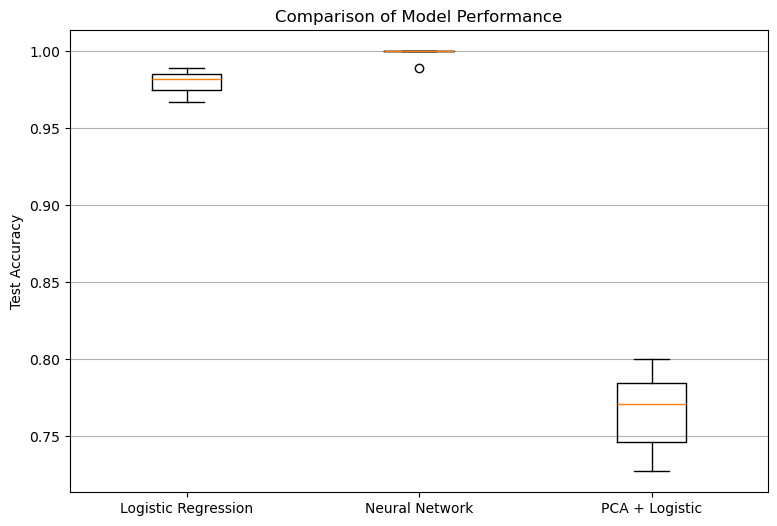

In [40]:
plt.figure(figsize=(9, 6))

plt.boxplot(
    [
        logistic_scores,
        nn_scores,
        pca_scores
    ],
    labels=[
        'Logistic Regression',
        'Neural Network',
        'PCA + Logistic'
    ]
)

plt.ylabel("Test Accuracy")
plt.title("Comparison of Model Performance")

plt.grid(axis='y')

plt.show()

In [41]:
final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Neural Network',
        'PCA + Logistic Regression'
    ],
    
    'Training Accuracy': [
        train_acc_l2,
        accuracy_score(y_train, nn_train_pred),
        pca_train_accuracy
    ],
    
    'Test Accuracy': [
        test_acc_l2,
        accuracy_score(y_test, nn_test_pred),
        pca_test_accuracy
    ],
    
    'Precision': [
        precision_score(y_test, test_pred_l2),
        precision_score(y_test, nn_test_pred),
        precision_score(y_test, pca_test_pred)
    ],
    
    'Recall': [
        recall_score(y_test, test_pred_l2),
        recall_score(y_test, nn_test_pred),
        recall_score(y_test, pca_test_pred)
    ],
    
    'F1 Score': [
        f1_score(y_test, test_pred_l2),
        f1_score(y_test, nn_test_pred),
        f1_score(y_test, pca_test_pred)
    ]
})

display(final_results)

,Model,Training Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.984503,0.970909,0.938462,1.000000,0.968254
1,Neural Network,1.000000,1.000000,1.000000,1.000000,1.000000
2,PCA + Logistic Regression,0.749316,0.796364,0.775000,0.762295,0.768595


In [42]:
best_model_index = final_results['Test Accuracy'].idxmax()

print("Best Model Based on Test Accuracy:")
print(final_results.loc[best_model_index, 'Model'])

print(
    "\nTest Accuracy:",
    final_results.loc[best_model_index, 'Test Accuracy']
)

Best Model Based on Test Accuracy:
Neural Network

Test Accuracy: 1.0
